# Taller 9

## 1. Librerías y reproducibilidad
Se fija una semilla y se emplean particiones estratificadas para conservar aproximadamente la proporción de cada dígito en entrenamiento y prueba.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB, CategoricalNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from sklearn.base import clone
RANDOM_STATE = 42
pd.set_option('display.precision', 4)

## 2. Carga y análisis del dataset
El conjunto digits reúne 1.797 imágenes de 8 × 8 píxeles (64 variables), etiquetadas con los dígitos del 0 al 9. La intensidad de cada píxel toma valores enteros entre 0 y 16, es decir, un conjunto finito de posibilidades. Además, como los píxeles vecinos guardan fuertes relaciones espaciales que el supuesto naive ignora, conviene esperar que ese supuesto no se cumpla.

X: (1797, 64) | y: (1797,)
Intensidades: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]
Distribución de clases: {np.int64(0): np.int64(178), np.int64(1): np.int64(182), np.int64(2): np.int64(177), np.int64(3): np.int64(183), np.int64(4): np.int64(181), np.int64(5): np.int64(182), np.int64(6): np.int64(181), np.int64(7): np.int64(179), np.int64(8): np.int64(174), np.int64(9): np.int64(180)}


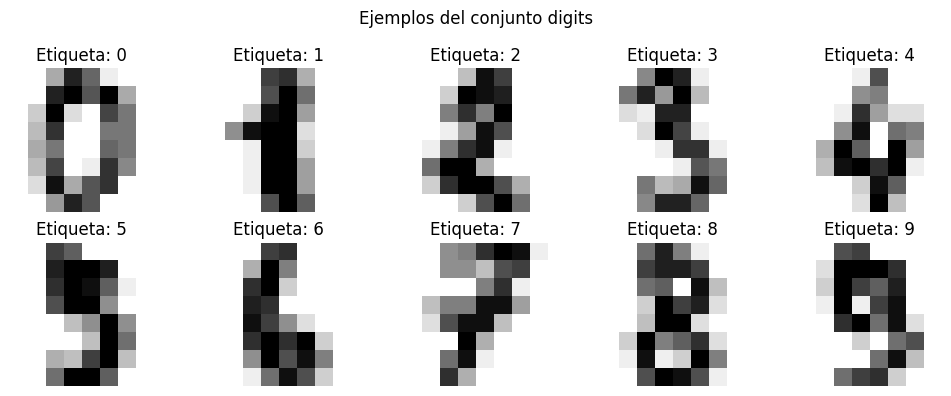

In [ ]:
digits = load_digits()
X, y = digits.data, digits.target
print('X:', X.shape, '| y:', y.shape)
print('Intensidades:', np.unique(X).astype(int))
print('Distribución de clases:', dict(zip(*np.unique(y, return_counts=True))))
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap='gray_r', interpolation='nearest')
    ax.set_title(f'Etiqueta: {y[i]}')
    ax.axis('off')
plt.suptitle('Ejemplos del conjunto digits')
plt.tight_layout()
plt.show()

## 3. Separación 80 % / 20 % y K-fold = 4
El conjunto de prueba **se reserva** hasta después de seleccionar el modelo y el valor de α. La comparación y el ajuste se hacen exclusivamente sobre los datos de entrenamiento mediante StratifiedKFold(n_splits=4).

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
print(f'Entrenamiento: {X_train.shape} ({len(y_train)/len(y):.1%})')
print(f'Prueba: {X_test.shape} ({len(y_test)/len(y):.1%})')

Entrenamiento: (1437, 64) (80.0%)
Prueba: (360, 64) (20.0%)


## 4. Fundamento probabilístico y comparación de distribuciones

Por el teorema de Bayes, la predicción corresponde a la clase con mayor probabilidad posterior:

$$\hat y=\arg\max_c\;P(y=c)\prod_{j=1}^{64}P(X_j=x_j\mid y=c).$$

Los cuatro modelos difieren en cómo tratan la distribución de cada píxel dentro de cada clase:

1-GaussianNB ajusta una normal a cada píxel. El problema es que bastantes píxeles se acumulan en cero y no tienen forma de campana simétrica, así que el ajuste es pobre en la práctica.

2-MultinomialNB parte de la idea de conteos no negativos. Las intensidades 0–16 no son literalmente conteos, pero al ser valores no negativos el modelo los acepta y suele dar resultados razonables.

3-BernoulliNB se limita a presencia/ausencia. Con binarize=0, cualquier píxel mayor que cero se convierte en 1, por lo que se pierde toda la información de los niveles de gris.

4-CategoricalNB trata cada píxel como una variable discreta con valores en {0, ..., 16}, que es exactamente el rango real de los datos. No resuelve el problema de dependencia entre píxeles, pero sí representa bien su naturaleza.

En el caso de CategoricalNB se fija min_categories=17 para que, aunque alguna partición no observe cierta intensidad en una columna, el modelo conserve las 17 categorías posibles. Para la comparación inicial se deja α = 1 en todos los casos.


In [ ]:
modelos = {
    'GaussianNB': GaussianNB(),
    'MultinomialNB': MultinomialNB(alpha=1.0),
    'BernoulliNB': BernoulliNB(alpha=1.0, binarize=0.0),
    'CategoricalNB': CategoricalNB(alpha=1.0, min_categories=17),
}
filas = []
for nombre, modelo in modelos.items():
    scores = cross_validate(
        modelo, X_train, y_train, cv=cv,
        scoring={'accuracy': 'accuracy', 'f1_macro': 'f1_macro',
                 'precision_macro': 'precision_macro', 'recall_macro': 'recall_macro'},
        n_jobs=1
    )
    filas.append({
        'Modelo': nombre,
        'Accuracy CV': scores['test_accuracy'].mean(),
        'Desv. estándar CV': scores['test_accuracy'].std(),
        'Precision macro CV': scores['test_precision_macro'].mean(),
        'Recall macro CV': scores['test_recall_macro'].mean(),
        'F1 macro CV': scores['test_f1_macro'].mean(),
    })
comparacion = pd.DataFrame(filas).sort_values('Accuracy CV', ascending=False).reset_index(drop=True)
print(comparacion.to_string(index=False))

       Modelo  Accuracy CV  Desv. estándar CV  Precision macro CV  Recall macro CV  F1 macro CV
CategoricalNB       0.9068             0.0170              0.9091           0.9064       0.9061
MultinomialNB       0.9047             0.0114              0.9121           0.9048       0.9050
  BernoulliNB       0.8546             0.0052              0.8597           0.8546       0.8535
   GaussianNB       0.8232             0.0050              0.8652           0.8233       0.8240


### Interpretación de la comparación
El criterio de selección es el accuracy promedio de validación cruzada, no el resultado sobre el conjunto de prueba. Con esta semilla, CategoricalNB logra el mejor promedio, aunque su diferencia frente a MultinomialNB es pequeña; hablar entonces de "superioridad" sería exagerado, sobre todo sin evidencia de significancia estadística. De todos modos, el resultado tiene sentido desde lo probabilístico: las intensidades son discretas, y CategoricalNB es el único que las modela como tales sin forzar ninguna suposición sobre conteos o normales.

## 5. Suavizado de Laplace y análisis de α
Para cada característica categórica, la estimación suavizada es:

$$P(X_j=v\mid y=c)=\frac{N_{c,j,v}+\alpha}{N_c+\alpha K_j},\qquad K_j=17.$$

`N_{c,j,v}` es el número de ejemplos de la clase `c` cuya característica `j` vale `v`; `N_c` es el número de ejemplos de la clase y `K_j` el número de categorías. Con **α=1** se aplica el suavizado aditivo clásico de Laplace. Valores positivos diferentes representan suavizado aditivo generalizado (por ejemplo, α=0,5, a veces llamado Lidstone). `α=0` se incluye solo como referencia sin suavizado, y puede causar probabilidades cero y avisos numéricos.

Un α pequeño conserva diferencias entre frecuencias observadas, pero puede producir estimaciones extremas para categorías raras. Un α grande acerca las distribuciones condicionales a la uniforme y puede reducir la capacidad discriminativa. El valor se elige por validación cruzada sin consultar el conjunto de prueba.

In [ ]:
alfas = [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0, 100.0]
resultados_alpha = []
for alpha in alfas:
    modelo = CategoricalNB(alpha=alpha, min_categories=17)
    scores = cross_validate(
        modelo, X_train, y_train, cv=cv,
        scoring={'accuracy': 'accuracy', 'f1_macro': 'f1_macro'}, n_jobs=1
    )
    resultados_alpha.append({
        'alpha': alpha, 'Accuracy CV': scores['test_accuracy'].mean(),
        'Desv. estándar': scores['test_accuracy'].std(),
        'F1 macro CV': scores['test_f1_macro'].mean()
    })
tabla_alpha = pd.DataFrame(resultados_alpha)
print(tabla_alpha.to_string(index=False))
mejor_alpha = float(tabla_alpha.loc[tabla_alpha['Accuracy CV'].idxmax(), 'alpha'])
print(f'\nMejor alpha según accuracy CV: {mejor_alpha}')

  alpha  Accuracy CV  Desv. estándar  F1 macro CV
  0.001       0.8928          0.0112       0.8932
  0.010       0.8970          0.0131       0.8972
  0.100       0.9061          0.0117       0.9061
  0.500       0.9088          0.0169       0.9085
  1.000       0.9068          0.0170       0.9061
  2.000       0.8970          0.0180       0.8964
  5.000       0.8859          0.0153       0.8853
 10.000       0.8636          0.0138       0.8632
 20.000       0.8386          0.0155       0.8355
 50.000       0.7933          0.0207       0.7874
100.000       0.7641          0.0245       0.7507

Mejor alpha según accuracy CV: 0.5


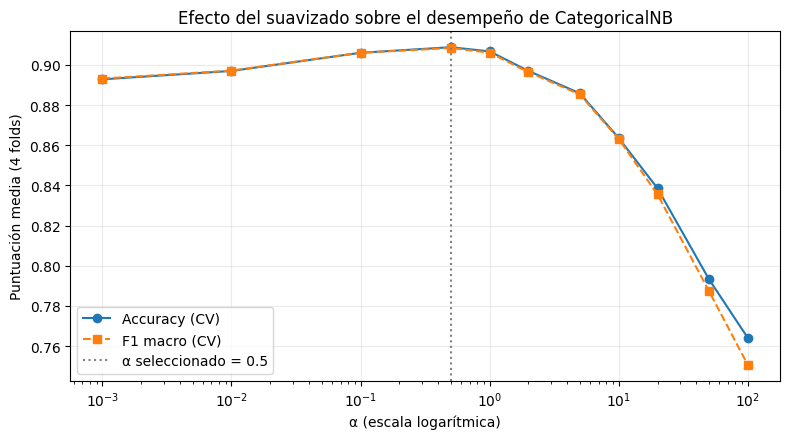

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tabla_alpha['alpha'], tabla_alpha['Accuracy CV'], 'o-', label='Accuracy (CV)')
ax.plot(tabla_alpha['alpha'], tabla_alpha['F1 macro CV'], 's--', label='F1 macro (CV)')
ax.axvline(mejor_alpha, linestyle=':', color='gray', label=f'α seleccionado = {mejor_alpha}')
ax.set_xscale('log')
ax.set_xlabel('α (escala logarítmica)')
ax.set_ylabel('Puntuación media (4 folds)')
ax.set_title('Efecto del suavizado sobre el desempeño de CategoricalNB')
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Entrenamiento definitivo y evaluación de prueba
Una vez elegido α, se reentrena `CategoricalNB` con **todo el 80 % de entrenamiento** y se evalúa una sola vez con el **20 % reservado**. Se reportan accuracy, precision, recall y F1 macro (promedio no ponderado de las 10 clases), matriz de confusión y clasificación por dígito.

In [ ]:
modelo_final = CategoricalNB(alpha=mejor_alpha, min_categories=17)
modelo_final.fit(X_train, y_train)
y_pred = modelo_final.predict(X_test)
print('MODELO FINAL: CategoricalNB')
print(f'α seleccionado: {mejor_alpha}')
print(f'Accuracy prueba: {accuracy_score(y_test, y_pred):.4f}')
print(f'Precision macro prueba: {precision_score(y_test, y_pred, average="macro", zero_division=0):.4f}')
print(f'Recall macro prueba: {recall_score(y_test, y_pred, average="macro", zero_division=0):.4f}')
print(f'F1 macro prueba: {f1_score(y_test, y_pred, average="macro", zero_division=0):.4f}')
print('\nREPORTE POR CLASE:')
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

MODELO FINAL: CategoricalNB
α seleccionado: 0.5
Accuracy prueba: 0.9111
Precision macro prueba: 0.9121
Recall macro prueba: 0.9108
F1 macro prueba: 0.9107

REPORTE POR CLASE:
              precision    recall  f1-score   support

           0     1.0000    0.9444    0.9714        36
           1     0.8056    0.8056    0.8056        36
           2     0.8919    0.9429    0.9167        35
           3     1.0000    1.0000    1.0000        37
           4     0.8718    0.9444    0.9067        36
           5     0.9706    0.8919    0.9296        37
           6     0.9714    0.9444    0.9577        36
           7     0.8974    0.9722    0.9333        36
           8     0.8788    0.8286    0.8529        35
           9     0.8333    0.8333    0.8333        36

    accuracy                         0.9111       360
   macro avg     0.9121    0.9108    0.9107       360
weighted avg     0.9126    0.9111    0.9112       360



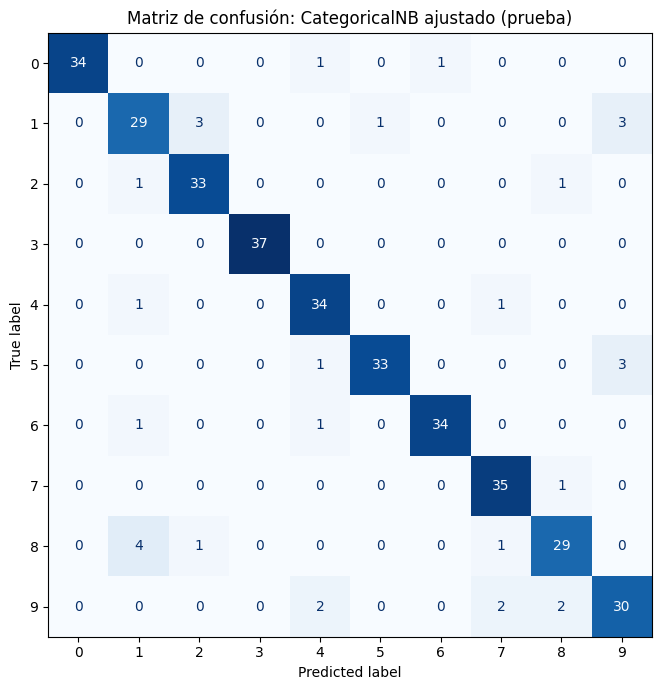

In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Matriz de confusión: CategoricalNB ajustado (prueba)')
plt.tight_layout()
plt.show()

## 7. Ejemplos de predicción y errores
Las siguientes imágenes provienen exclusivamente del conjunto de prueba. Se muestran ejemplos con sus etiquetas reales y predichas.

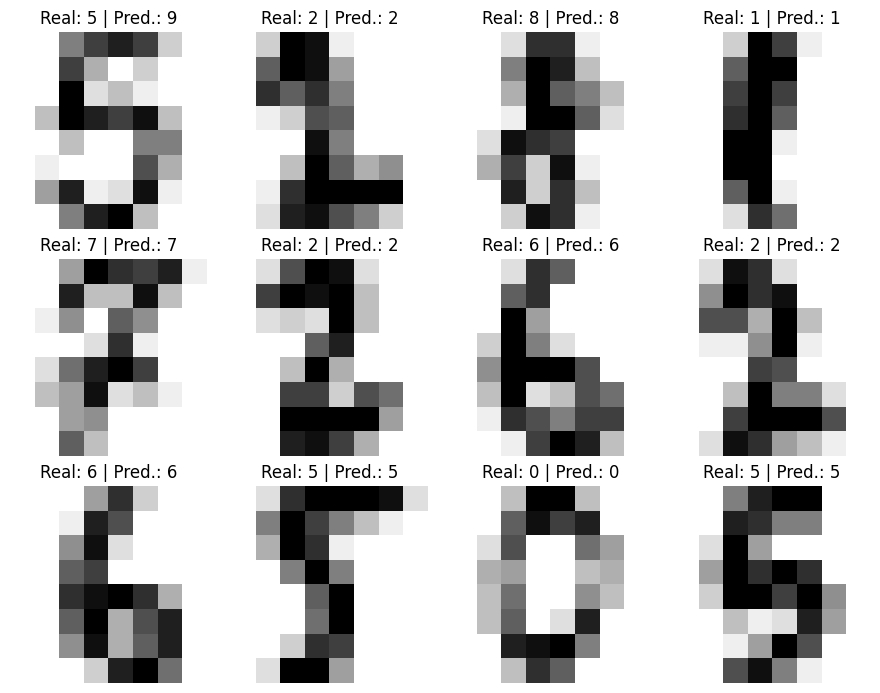

Errores: 32 de 360 imágenes


In [ ]:
indices = np.arange(min(12, len(y_test)))
fig, axes = plt.subplots(3, 4, figsize=(9, 7))
for ax, idx in zip(axes.flat, indices):
    ax.imshow(X_test[idx].reshape(8, 8), cmap='gray_r')
    ax.set_title(f'Real: {y_test[idx]} | Pred.: {y_pred[idx]}')
    ax.axis('off')
plt.tight_layout()
plt.show()
mal = np.flatnonzero(y_test != y_pred)
print(f'Errores: {len(mal)} de {len(y_test)} imágenes')

## 8. Conclusiones

1-`digits` tiene píxeles de intensidad entera 0–16: los datos se prestan naturalmente a representaciones categóricas. Esto **no implica** que cada píxel siga una distribución multinomial ni que los píxeles sean independientes.

2- En los cuatro métodos estudiados y bajo este protocolo de validación, **CategoricalNB** presenta el mejor accuracy medio de validación cruzada con α inicial de 1, aunque supera a `MultinomialNB` por un margen pequeño.

3- El suavizado evita asignar probabilidad condicional nula a categorías no observadas. En el experimento, el mejor α dentro de la malla es **0,5** según accuracy medio CV; **α=1** es específicamente el suavizado clásico de Laplace. No debe confundirse «aplicar Laplace» con afirmar que 0,5 sea Laplace clásico.

4- Con valores muy elevados de α se observa pérdida de exactitud, compatible con la reducción del contraste entre frecuencias condicionales.

5- La evaluación del conjunto de prueba se hace después de la selección para evitar usar esos datos en el ajuste. Los resultados están condicionados a la partición y semilla empleadas.
